# Лабораторна робота № 4

**Дисципліна:** Інтелектуальний аналіз даних  
**Варіант:** 20(10)   
**Студентка:** Софія Посікера  
**Група:** МІТ-31

## Тема

**Бінарна класифікація табличних даних на прикладі Titanic**

## Мета роботи

Навчитися виконувати повний цикл бінарної класифікації: сформулювати ціль, дослідити дані, створити відтворюваний стратифікований поділ, побудувати базову й основну моделі, уникнути витоку даних, оцінити прогнози за кількома метриками та обґрунтувати вибір порога рішення.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Первинний аналіз даних ##

In [2]:
print(df.shape)
display(df.head())
df.info()
display(df.describe(include="all"))
print("Дублікати:", df.duplicated().sum())

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 116.9 KB


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Дублікати: 107


## Графік — виживання за статтю ##

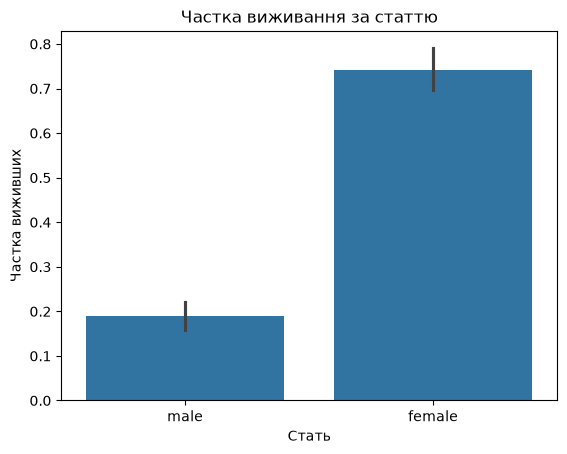

In [18]:
sns.barplot(data=df, x="sex", y="survived")
plt.title("Частка виживання за статтю")
plt.xlabel("Стать")
plt.ylabel("Частка виживших")
plt.show()

## Графік — виживання за класом квитка ##

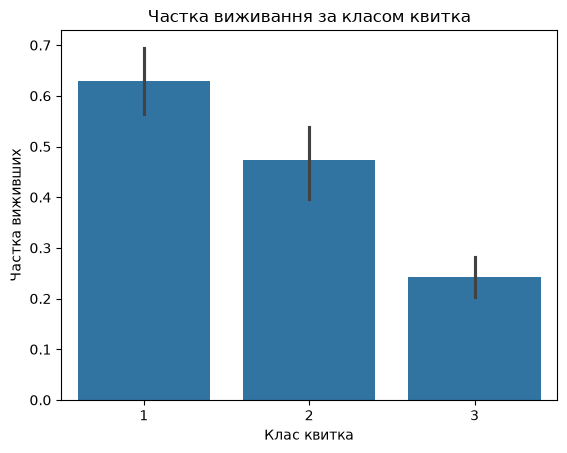

In [19]:
sns.barplot(data=df, x="pclass", y="survived")
plt.title("Частка виживання за класом квитка")
plt.xlabel("Клас квитка")
plt.ylabel("Частка виживших")
plt.show()

## Аналіз пропущених значень та балансу класів ##

In [3]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": df.isna().mean().mul(100)
}).sort_values("percent", ascending=False)

class_balance = df["survived"].value_counts(normalize=True).sort_index()
display(missing, class_balance)

,count,percent
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000


survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

## Формування ознак і цілі ##

In [4]:
data = df.copy()
data["family_size"] = data["sibsp"] + data["parch"] + 1

numeric_features = ["age", "sibsp", "parch", "fare", "family_size"]
categorical_features = ["pclass", "sex", "embarked"]

X = data[numeric_features + categorical_features]
y = data["survived"]


## Навчальна і тестова вибірки ##

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print("Усі дані:", y.mean())
print("Навчальна вибірка:", y_train.mean())
print("Тестова вибірка:", y_test.mean())


Усі дані: 0.3838383838383838
Навчальна вибірка: 0.38342696629213485
Тестова вибірка: 0.3854748603351955


## Базова модель ##

In [6]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)


## Підготовка ознак у Pipeline ##

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

model = Pipeline([
    ("prepare", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])


## Навчання та прогноз ##

In [9]:
model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['age','sibsp','parch',...,'pclass','sex','embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns th

In [10]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

## Оцінювання ##

In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)

def classification_metrics(y_true, y_hat):
    return {
        "accuracy": accuracy_score(y_true, y_hat),
        "precision": precision_score(y_true, y_hat, zero_division=0),
        "recall": recall_score(y_true, y_hat, zero_division=0),
        "f1": f1_score(y_true, y_hat, zero_division=0),
    }


In [13]:
results = pd.DataFrame([
    classification_metrics(y_test, baseline_pred),
    classification_metrics(y_test, y_pred),
], index=["DummyClassifier", "LogisticRegression"])

results.loc["LogisticRegression", "roc_auc"] = roc_auc_score(y_test, y_proba)
results.loc["LogisticRegression", "average_precision"] = average_precision_score(y_test, y_proba)
display(results.round(3))


,accuracy,precision,recall,f1,roc_auc,average_precision
DummyClassifier,0.615,0.000,0.000,0.000,NaN,NaN
LogisticRegression,0.804,0.793,0.667,0.724,0.843,0.786


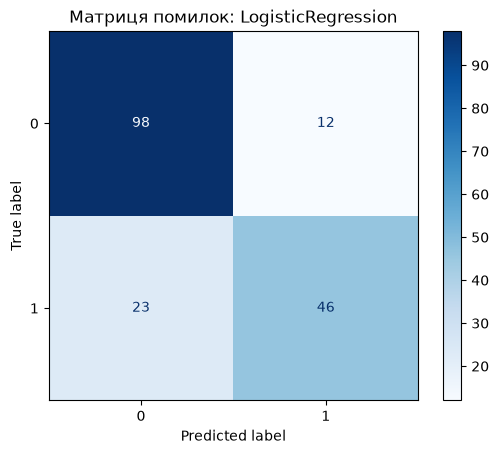

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Матриця помилок: LogisticRegression")
plt.show()

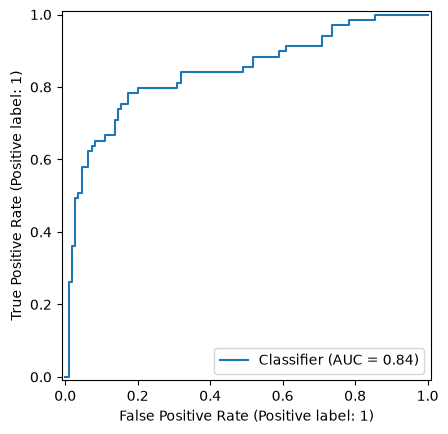

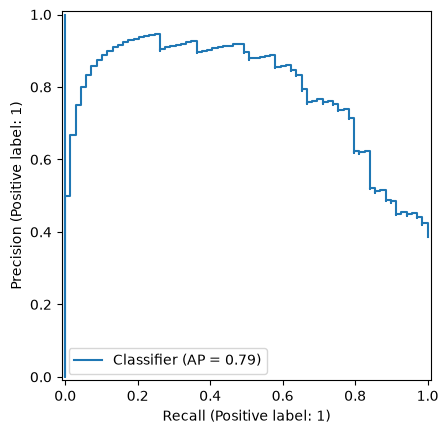

In [15]:
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, y_proba)
plt.show()

## Аналіз порога рішення ##

In [16]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    pred_t = (y_proba >= threshold).astype(int)
    row = classification_metrics(y_test, pred_t)
    row["threshold"] = threshold
    threshold_rows.append(row)

threshold_results = pd.DataFrame(threshold_rows).set_index("threshold")
display(threshold_results.round(3))

,accuracy,precision,recall,f1
threshold,,,,
0.3,0.771,0.671,0.797,0.728
0.5,0.804,0.793,0.667,0.724
0.7,0.788,0.897,0.507,0.648


## Аналіз окремих помилок ##

In [17]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred
error_analysis["probability"] = y_proba

false_positive = error_analysis.query("actual == 0 and predicted == 1")
false_negative = error_analysis.query("actual == 1 and predicted == 0")

display(false_positive.sort_values("probability", ascending=False).head())
display(false_negative.sort_values("probability").head())


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
297,2.0,1,2,151.5500,4,1,female,S,0,1,0.965727
199,24.0,0,0,13.0000,1,2,female,S,0,1,0.838099
501,21.0,0,0,7.7500,1,3,female,Q,0,1,0.772259
502,NaN,0,0,7.6292,1,3,female,Q,0,1,0.718875
593,NaN,0,2,7.7500,3,3,female,Q,0,1,0.683636


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
570,62.0,0,0,10.5000,1,2,male,S,1,0,0.083417
444,NaN,0,0,8.1125,1,3,male,S,1,0,0.087915
804,27.0,0,0,6.9750,1,3,male,S,1,0,0.092276
146,27.0,0,0,7.7958,1,3,male,S,1,0,0.092468
271,25.0,0,0,0.0000,1,3,male,S,1,0,0.097051


## Індивідуальні варіант 10 ##
Побудувати permutation importance і пояснити п’ять найважливіших ознак без причинних тверджень.

In [20]:
from sklearn.inspection import permutation_importance

In [21]:
perm_importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=SEED
)

In [22]:
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_importance.importances_mean,
    "importance_std": perm_importance.importances_std
})

importance = importance.sort_values(
    "importance_mean",
    ascending=False
)

display(importance)

,feature,importance_mean,importance_std
6,sex,0.282976,0.063472
5,pclass,0.094762,0.030827
1,sibsp,0.023753,0.010822
0,age,0.017328,0.020083
4,family_size,0.014234,0.004729
3,fare,0.014093,0.009883
2,parch,0.000000,0.000000
7,embarked,-0.010426,0.011791


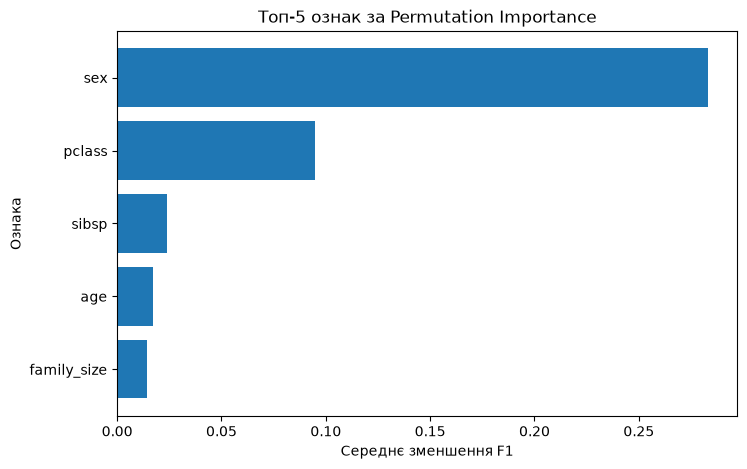

In [23]:
top5 = importance.head(5).sort_values("importance_mean")

plt.figure(figsize=(8, 5))
plt.barh(top5["feature"], top5["importance_mean"])
plt.xlabel("Середнє зменшення F1")
plt.ylabel("Ознака")
plt.title("Топ-5 ознак за Permutation Importance")
plt.show()

### Пояснення п'яти найважливіших ознак

За результатами Permutation Importance п'ять ознак із найбільшим середнім значенням важливості для F1 моделі — `sex`, `pclass`, `sibsp`, `age` та `family_size`.

- **`sex`** — має найбільше значення Permutation Importance (`0.283`). Перемішування цієї ознаки найбільше зменшувало F1, тому для побудованої моделі вона була найбільш важливою серед використаних ознак.
- **`pclass`** — друге за величиною значення (`0.095`). Її перемішування також помітно погіршувало F1 моделі.
- **`sibsp`** — має значення `0.024`. Перемішування цієї ознаки спричиняло невелике зниження F1.
- **`age`** — має значення `0.017`. Її перемішування також дещо впливало на якість прогнозування за F1.
- **`family_size`** — має значення `0.014`. Перемішування цієї ознаки давало невелике зниження F1.

Отже, для побудованої Logistic Regression найбільше значення за permutation importance мала ознака `sex`, після неї — `pclass`. Інші три ознаки з топ-5 мали значно менші значення важливості. Отримані результати характеризують внесок ознак у роботу саме цієї моделі на тестовій вибірці та не означають наявності причинно-наслідкового зв'язку.